# Practical 11: Decision Tree and Random Forest – Bank Marketing

**Aim:** To implement Decision Tree and Random Forest classifiers on the Bank Marketing dataset and compare their accuracy and overfitting behavior.

**Dataset:** [Bank Marketing Dataset – Kaggle](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset)

Download `bank.csv` and keep it in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv("bank.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [4]:
# Convert categorical columns into numbers
df = pd.get_dummies(df, drop_first=True)
df.head()

,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,deposit_yes
0,59,2343,5,1042,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,True,True
1,56,45,5,1467,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,True,True
2,41,1270,5,1389,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,True,True
3,55,2476,5,579,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,True,True
4,54,184,5,673,2,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,True,True


In [5]:
# Create input and output data
X = df.drop("deposit_yes", axis=1)
X[:3]

,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,59,2343,5,1042,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,56,45,5,1467,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,41,1270,5,1389,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [6]:
y = df["deposit_yes"]
y[:3]

0    True
1    True
2    True
Name: deposit_yes, dtype: bool

In [7]:
# Splitting the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [8]:
# Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [9]:
# Decision Tree accuracy
print("Decision Tree Training Accuracy:", dt.score(X_train, y_train) * 100)
print("Decision Tree Testing Accuracy:", dt.score(X_test, y_test) * 100)

Decision Tree Training Accuracy: 100.0
Decision Tree Testing Accuracy: 79.22077922077922


In [10]:
# Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [11]:
# Random Forest accuracy
print("Random Forest Training Accuracy:", rf.score(X_train, y_train) * 100)
print("Random Forest Testing Accuracy:", rf.score(X_test, y_test) * 100)

Random Forest Training Accuracy: 100.0
Random Forest Testing Accuracy: 86.25167935512764


In [12]:
# Compare both models
result = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [dt.score(X_train, y_train) * 100,
                          rf.score(X_train, y_train) * 100],
    "Testing Accuracy": [dt.score(X_test, y_test) * 100,
                         rf.score(X_test, y_test) * 100]
})

result

,Model,Training Accuracy,Testing Accuracy
0,Decision Tree,100.0,79.220779
1,Random Forest,100.0,86.251679


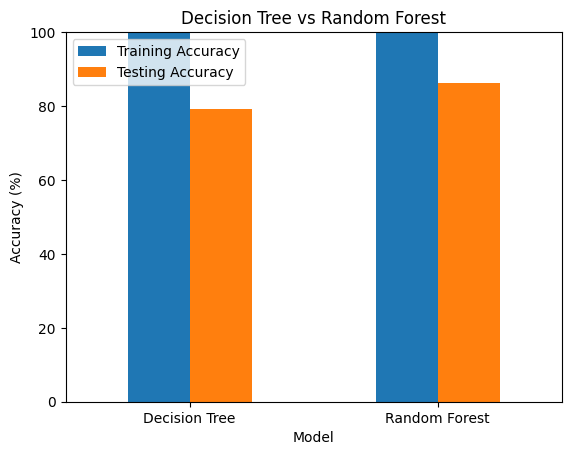

In [13]:
# Plot accuracy comparison
result.set_index("Model").plot(kind="bar")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree vs Random Forest")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

In [14]:
# Confusion matrix and classification report
from sklearn.metrics import confusion_matrix, classification_report

y_pred = rf.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[986 189]
 [118 940]]
              precision    recall  f1-score   support

       False       0.89      0.84      0.87      1175
        True       0.83      0.89      0.86      1058

    accuracy                           0.86      2233
   macro avg       0.86      0.86      0.86      2233
weighted avg       0.86      0.86      0.86      2233



## Conclusion

Decision Tree and Random Forest classifiers were implemented on the Bank Marketing dataset. Their training and testing accuracies were compared. A large difference between training and testing accuracy indicates overfitting. Random Forest combines multiple decision trees and can reduce overfitting compared with a single Decision Tree.